# Customer Segmentation Using RFM Analysis

Not all customers are equally valuable to a business. In this project I group the customers of a UK online retailer by how they buy, using three measures:

- **Recency (R):** days since the customer's last purchase (lower is better)
- **Frequency (F):** number of separate orders the customer placed
- **Monetary (M):** total amount the customer spent

Every customer gets a score from 1 to 5 on each measure. I use those scores to place customers into segments such as *Champions*, *At Risk* and *Hibernating*, and I suggest a marketing action for each segment.

**Dataset:** [Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii) (UCI Machine Learning Repository): 1,067,371 transactions, December 2009 to December 2011
**Tools:** Python, Pandas, Matplotlib, Seaborn

## Step 1: Load the data

Upload `online_retail_II.csv` to the Colab **Files** panel before running this cell.

- `dtype=str` keeps `Invoice`, `StockCode` and `Customer ID` as text, so codes like `79323P` and cancelled invoices like `C489449` are read correctly.
- `parse_dates` turns `InvoiceDate` into real dates, which are needed to calculate Recency.

In [ ]:
import pandas as pd

df = pd.read_csv('online_retail_II.csv',
                 dtype={'Invoice': str, 'StockCode': str, 'Customer ID': str},
                 parse_dates=['InvoiceDate'])
print(df.shape)
df.head()

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## Step 2: Check data quality

Before cleaning, I check the date range, missing values, duplicates, and rows that are not real purchases.

In [ ]:
print(df['InvoiceDate'].min(), df['InvoiceDate'].max())
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Cancelled invoices:", df['Invoice'].str.startswith('C').sum())
print("Quantity <= 0:", (df['Quantity'] <= 0).sum())
print("Price <= 0:", (df['Price'] <= 0).sum())

2009-12-01 07:45:00 2011-12-09 12:50:00
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64
Duplicate rows: 34335
Cancelled invoices: 19494
Quantity <= 0: 22950
Price <= 0: 6207


**Findings:**

| Check | Rows |
|---|---|
| Date range | 1 Dec 2009 to 9 Dec 2011 |
| Missing `Customer ID` | 243,007 (about 23%) |
| Missing `Description` | 4,382 |
| Duplicate rows | 34,335 |
| Cancelled invoices (start with "C") | 19,494 |
| Quantity ≤ 0 | 22,950 |
| Price ≤ 0 | 6,207 |

These groups overlap (most cancellations also have a negative quantity), so I remove them one step at a time and record how many rows remain after each step.

## Step 3: Clean the data

RFM is calculated per customer and must only count real purchases, so I:

1. Remove rows with no `Customer ID`, because they can't be linked to a customer
2. Remove cancelled invoices, which are returns rather than purchases
3. Keep only rows with a positive quantity and price
4. Remove duplicate rows, so spending is not double-counted
5. Fix `Customer ID` values stored as `13085.0` → `13085`
6. Add `TotalPrice` = Quantity × Price, the amount spent on each line

In [ ]:
clean = df.copy()
print("Start:", len(clean))

clean = clean.dropna(subset=['Customer ID'])
print("After removing missing Customer ID:", len(clean))

clean = clean[~clean['Invoice'].str.startswith('C')]
print("After removing cancellations:", len(clean))

clean = clean[(clean['Quantity'] > 0) & (clean['Price'] > 0)]
print("After removing zero/negative quantity & price:", len(clean))

clean = clean.drop_duplicates()
print("After removing duplicates:", len(clean))

clean['Customer ID'] = clean['Customer ID'].str.replace(r'\.0$', '', regex=True)
clean['TotalPrice'] = clean['Quantity'] * clean['Price']

print("Customers:", clean['Customer ID'].nunique())
clean.head()

Start: 1067371
After removing missing Customer ID: 824364
After removing cancellations: 805620
After removing zero/negative quantity & price: 805549
After removing duplicates: 779425
Customers: 5878


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


**Cleaning log:**

| Step | Rows remaining | Rows removed |
|---|---|---|
| Raw data | 1,067,371 | |
| Remove missing Customer ID | 824,364 | 243,007 |
| Remove cancellations | 805,620 | 18,744 |
| Remove zero/negative quantity & price | 805,549 | 71 |
| Remove duplicates | 779,425 | 26,124 |

**Result:** 779,425 clean transactions from **5,878 customers**.

## Step 4: Calculate Recency, Frequency and Monetary value

Because the data is historical, "today" (the snapshot date) is set to the day after the last purchase in the data. Recency is measured from that date.

In [ ]:
# "Today" = the day after the last purchase in the data
snapshot_date = clean['InvoiceDate'].max() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot_date)

rfm = clean.groupby('Customer ID').agg(
    Recency   = ('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency = ('Invoice', 'nunique'),
    Monetary  = ('TotalPrice', 'sum')
)

print(rfm.shape)
rfm.describe()

Snapshot date: 2011-12-10 12:50:00
(5878, 3)


,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000
mean,201.331916,6.289384,2955.904095
std,209.338707,13.009406,14440.852688
min,1.000000,1.000000,2.950000
25%,26.000000,1.000000,342.280000
50%,96.000000,3.000000,867.740000
75%,380.000000,7.000000,2248.305000
max,739.000000,398.000000,580987.040000


**What the numbers show:**

- **Recency:** the median customer last bought 96 days before the snapshot, and a quarter haven't bought for over a year (380+ days).
- **Frequency:** the median is 3 orders, and at least a quarter of customers ordered only once.
- **Monetary:** the median customer spent £868, but the mean is £2,956 and the largest spent £580,987. A few very large buyers pull the average up, which is why the next step uses scores instead of raw values.

## Step 5: Score customers from 1 to 5

`pd.qcut` splits customers into five equal-sized groups (quintiles): the top 20% score 5 and the bottom 20% score 1.

- **Recency** labels are reversed, because a recent purchase (few days) is better.
- **Frequency** is ranked first, because over a fifth of customers have exactly 1 order and `qcut` can't split identical values into 5 groups.
- **RFM_Score** joins the three scores (for example `555` = best customers), and **RFM_Total** adds them (3 to 15).

In [ ]:
# Recency: lower days = better, so the labels are reversed (5 = most recent)
rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)

# Frequency: many customers have exactly 1 order, so rank first to break ties
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Monetary: higher spend = better
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Combined scores
rfm['RFM_Score'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)
rfm['RFM_Total'] = rfm[['R_Score', 'F_Score', 'M_Score']].sum(axis=1)

rfm.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total
Customer ID,,,,,,,,
12346,326,12,77556.46,2,5,5,255,12
12347,2,8,4921.53,5,4,5,545,14
12348,75,5,2019.40,3,4,4,344,11
12349,19,4,4428.69,5,3,5,535,13
12350,310,1,334.40,2,1,2,212,5
12351,375,1,300.93,2,1,2,212,5
12352,36,10,2849.84,4,5,4,454,13
12353,204,2,406.76,2,2,2,222,6
12354,232,1,1079.40,2,1,3,213,6


For example, customer **12347** (`545`) bought 2 days ago, orders often and spends a lot. Customer **12346** (`255`) spent £77,556 but hasn't bought for 326 days, so they're a valuable customer at risk of being lost.

## Step 6: Group customers into segments

Segments are based on the **R and F scores**, which describe behaviour (how recently and how often a customer buys). Monetary value is then used to compare how much each segment is worth.

| Segment | Rule |
|---|---|
| Champions | R = 5, F ≥ 4 |
| Loyal Customers | R ≥ 3, F ≥ 4 |
| Potential Loyalists | R ≥ 4, F = 2–3 |
| New Customers | R = 5, F = 1 |
| Promising | R = 4, F = 1 |
| Need Attention | R = 3, F = 3 |
| About to Sleep | R = 3, F ≤ 2 |
| Can't Lose Them | R ≤ 2, F = 5 |
| At Risk | R ≤ 2, F = 3–4 |
| Hibernating | everyone else (R ≤ 2, F ≤ 2) |

In [ ]:
def segment(row):
    r, f = row['R_Score'], row['F_Score']
    if r == 5 and f >= 4:
        return 'Champions'
    elif r >= 3 and f >= 4:
        return 'Loyal Customers'
    elif r >= 4 and f in (2, 3):
        return 'Potential Loyalists'
    elif r == 5 and f == 1:
        return 'New Customers'
    elif r == 4 and f == 1:
        return 'Promising'
    elif r == 3 and f == 3:
        return 'Need Attention'
    elif r == 3 and f <= 2:
        return 'About to Sleep'
    elif r <= 2 and f == 5:
        return "Can't Lose Them"
    elif r <= 2 and f in (3, 4):
        return 'At Risk'
    else:
        return 'Hibernating'

rfm['Segment'] = rfm.apply(segment, axis=1)

# Summary of each segment
summary = rfm.groupby('Segment').agg(
    Customers     = ('Recency', 'count'),
    Avg_Recency   = ('Recency', 'mean'),
    Avg_Frequency = ('Frequency', 'mean'),
    Avg_Monetary  = ('Monetary', 'mean'),
    Total_Revenue = ('Monetary', 'sum')
).round(1)

summary['% Customers'] = (summary['Customers'] / summary['Customers'].sum() * 100).round(1)
summary['% Revenue']   = (summary['Total_Revenue'] / summary['Total_Revenue'].sum() * 100).round(1)
summary.sort_values('Total_Revenue', ascending=False)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,% Customers,% Revenue
Segment,,,,,,,
Champions,837,8.6,19.3,10646.5,8911085.8,14.2,51.3
Loyal Customers,1161,67.1,9.8,4138.8,4805172.8,19.8,27.7
At Risk,753,372.7,3.9,1348.3,1015248.4,12.8,5.8
Potential Loyalists,714,25.8,2.6,1142.7,815892.0,12.1,4.7
Hibernating,1523,459.3,1.3,429.7,654426.7,25.9,3.8
Can't Lose Them,71,331.2,15.9,8086.4,574135.9,1.2,3.3
Need Attention,266,113.4,3.2,1273.7,338799.3,4.5,1.9
About to Sleep,385,107.1,1.4,530.8,204349.7,6.5,1.2
Promising,114,38.8,1.0,318.1,36267.3,1.9,0.2


**Key findings:**

- **Revenue is highly concentrated.** Champions are **14.2% of customers but 51.3% of revenue** (£8.9M). Together with Loyal Customers, about **34% of customers produce 79% of revenue**.
- **A quarter of customers are inactive.** Hibernating is the largest segment (1,523 customers, 25.9%) but brings in only 3.8% of revenue.
- **Valuable customers are slipping away.** *At Risk* (753 customers, £1.0M) and *Can't Lose Them* (71 customers averaging £8,086 and 16 orders each) used to buy a lot but haven't purchased for around a year.

## Step 7: Marketing actions for each segment

In [ ]:
actions = {
    'Champions':           'Reward them: VIP program, early access to new products, ask for reviews/referrals',
    'Loyal Customers':     'Upsell higher-value products, loyalty points, personalised recommendations',
    'Potential Loyalists': 'Offer membership or loyalty program, recommend related products',
    'New Customers':       'Welcome email series, onboarding tips, small discount on 2nd order',
    'Promising':           'Build awareness: free shipping offer, highlight best-sellers',
    'Need Attention':      'Limited-time offers based on past purchases',
    'About to Sleep':      'Re-engage with popular products and a "we miss you" discount',
    'At Risk':             'Personalised win-back emails, special discounts, ask for feedback',
    "Can't Lose Them":     'High-priority win-back: personal outreach, exclusive offers, find out why they left',
    'Hibernating':         'Low-cost re-activation campaign; remove from regular mailing if no response'
}

summary['Marketing Action'] = summary.index.map(actions)
summary.sort_values('Total_Revenue', ascending=False)[['Customers', '% Customers', '% Revenue', 'Marketing Action']]

,Customers,% Customers,% Revenue,Marketing Action
Segment,,,,
Champions,837,14.2,51.3,"Reward them: VIP program, early access to new ..."
Loyal Customers,1161,19.8,27.7,"Upsell higher-value products, loyalty points, ..."
At Risk,753,12.8,5.8,"Personalised win-back emails, special discount..."
Potential Loyalists,714,12.1,4.7,"Offer membership or loyalty program, recommend..."
Hibernating,1523,25.9,3.8,Low-cost re-activation campaign; remove from r...
Can't Lose Them,71,1.2,3.3,"High-priority win-back: personal outreach, exc..."
Need Attention,266,4.5,1.9,Limited-time offers based on past purchases
About to Sleep,385,6.5,1.2,"Re-engage with popular products and a ""we miss..."
Promising,114,1.9,0.2,"Build awareness: free shipping offer, highligh..."


## Step 8: Visualise the segments

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Segments ordered from highest to lowest revenue, used by the charts below
order = summary.sort_values('Total_Revenue', ascending=False).index

### Share of customers vs share of revenue

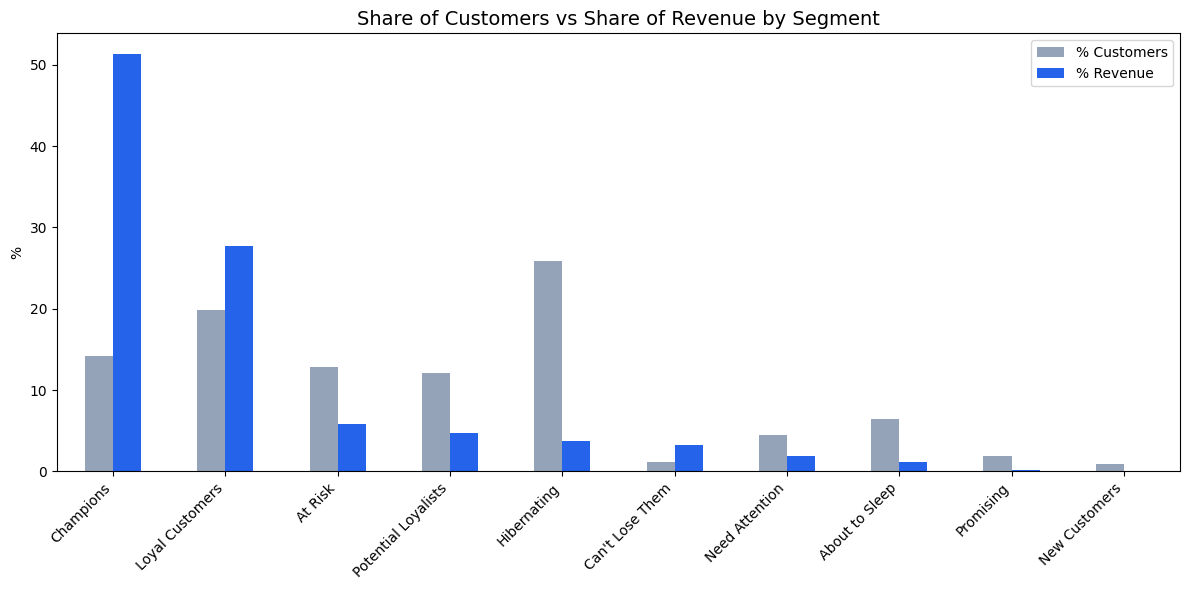

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
summary.loc[order, ['% Customers', '% Revenue']].plot(kind='bar', ax=ax, color=['#94a3b8', '#2563eb'])
ax.set_title('Share of Customers vs Share of Revenue by Segment', fontsize=14)
ax.set_ylabel('%')
ax.set_xlabel('')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('segment_share.png', dpi=150, bbox_inches='tight')   # ← here
plt.show()

Champions have the biggest gap: a small share of customers but over half of all revenue. Hibernating is the opposite. *Can't Lose Them* is the only small segment whose revenue share is larger than its customer share, which shows how valuable those 71 customers were.

### Heatmap: average spend by Recency and Frequency score

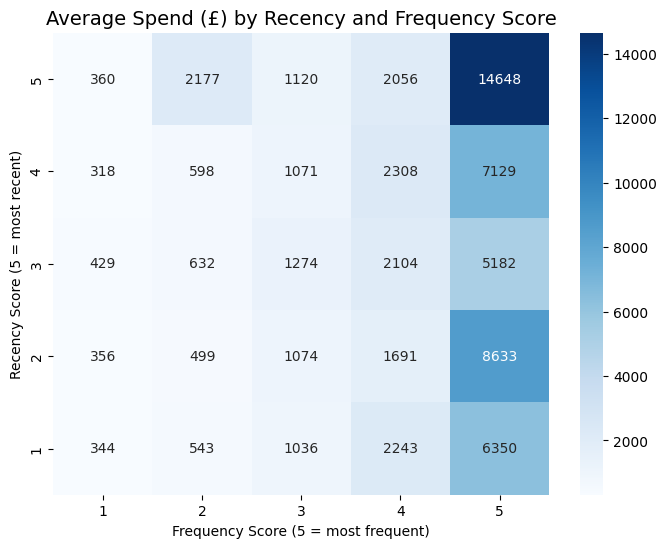

In [ ]:
heat = rfm.pivot_table(index='R_Score', columns='F_Score', values='Monetary', aggfunc='mean')
plt.figure(figsize=(8, 6))
sns.heatmap(heat.sort_index(ascending=False), annot=True, fmt='.0f', cmap='Blues')
plt.title('Average Spend (£) by Recency and Frequency Score', fontsize=14)
plt.xlabel('Frequency Score (5 = most frequent)')
plt.ylabel('Recency Score (5 = most recent)')
plt.savefig('rfm_heatmap.png', dpi=150, bbox_inches='tight')     # ← here
plt.show()

Average spend rises sharply from left to right, so **frequency is the strongest sign of a high-value customer**: F = 5 customers spend £5,000–£14,600 on average, compared with about £350 for F = 1. The darkest cell (R = 5, F = 5, £14,648) is the Champions. The cell R = 2, F = 5 (£8,633) is the *Can't Lose Them* group: big, frequent buyers who have gone quiet, which makes them the top priority for a win-back campaign.

### Donut charts: customers vs revenue

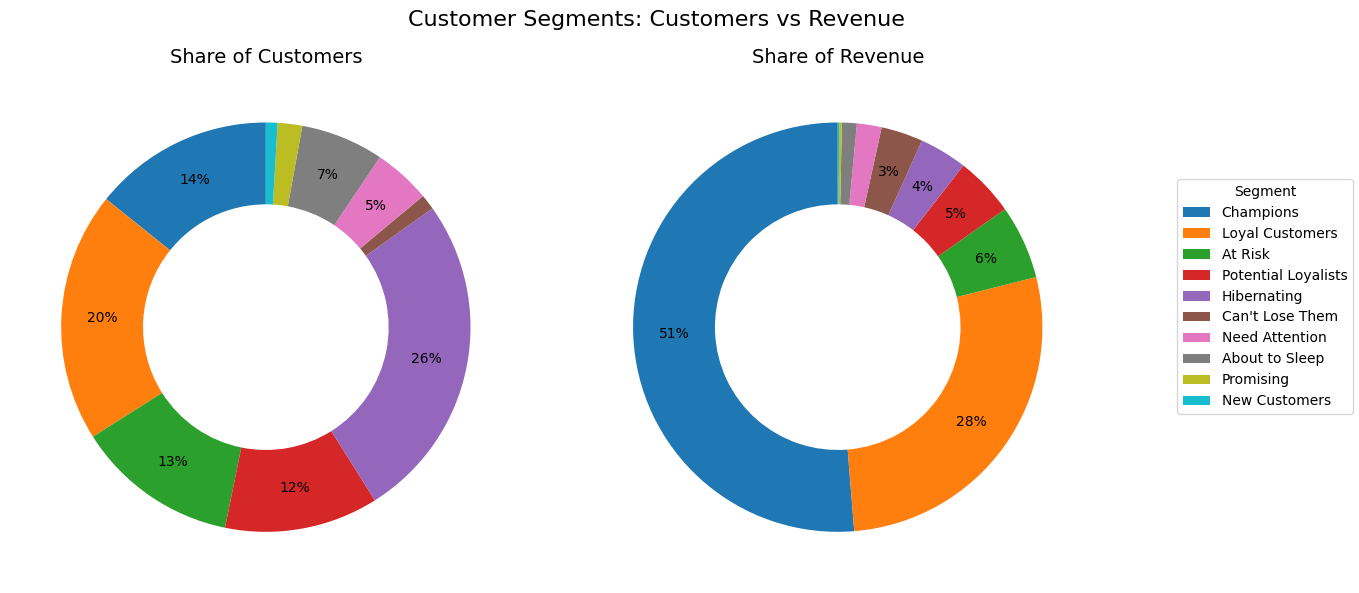

In [ ]:
segments = summary.sort_values('Total_Revenue', ascending=False).index
colors = sns.color_palette('tab10', len(segments))

def show_pct(p):
    return f'{p:.0f}%' if p >= 3 else ''   # hide labels on tiny slices

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].pie(summary.loc[segments, 'Customers'], colors=colors, autopct=show_pct,
            startangle=90, pctdistance=0.8, wedgeprops={'width': 0.4})
axes[0].set_title('Share of Customers', fontsize=14)

axes[1].pie(summary.loc[segments, 'Total_Revenue'], colors=colors, autopct=show_pct,
            startangle=90, pctdistance=0.8, wedgeprops={'width': 0.4})
axes[1].set_title('Share of Revenue', fontsize=14)

fig.legend(segments, loc='center right', title='Segment')
plt.suptitle('Customer Segments: Customers vs Revenue', fontsize=16)
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.savefig('segment_pie.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 9: Save the results

In [ ]:
rfm.to_csv('rfm_customers.csv')
summary.to_csv('rfm_segment_summary.csv')

## Conclusion

- **5,878 customers** were scored and grouped into 10 segments.
- **Champions and Loyal Customers (34% of customers) generate 79% of revenue**, so keeping them happy is the top priority: VIP rewards, early access and personalised recommendations.
- **Can't Lose Them and At Risk customers** were once high-value but have stopped buying. A targeted win-back campaign (personal outreach, exclusive offers, feedback requests) could recover a large share of the £1.6M they have spent.
- **Hibernating customers** (26%) bring little revenue, so low-cost re-activation emails are enough. Customers who don't respond can be removed from regular campaigns to save marketing cost.

## Step 10 (optional): Interactive dashboard with Streamlit

The cells below write a branded dashboard app, start it inside Colab, and print a temporary public link. The link only works while this Colab session is running. For a permanent link, deploy `app.py` on Streamlit Community Cloud.

The dashboard uses **Maple & Thread Gifts**, a fictional brand created for this demo. Change `BRAND_NAME`, the colours, or add a `logo.png` in the branding block at the top of `app.py` to rebrand it.


In [ ]:
!pip install -q streamlit plotly

In [ ]:
%%writefile app.py
"""
Customer Segmentation Dashboard (RFM Analysis)
Run locally:  streamlit run app.py
Data:         rfm_customers.csv (saved by rfm_analysis.ipynb, Step 9)
"""
import os

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st

# =====================================================================
# BRANDING: change these to rebrand the whole dashboard
# =====================================================================
BRAND_NAME = "Maple & Thread Gifts"          # fictional demo brand
TAGLINE = "Customer Insights · RFM Segmentation"
PRIMARY = "#4338CA"      # indigo: headers, main bars
ACCENT = "#FB7185"       # coral: highlights
GOLD = "#818CF8"         # periwinkle: secondary accent
DARK = "#1E1B4B"         # deep indigo: sidebar, header, text
LIGHT = "#F5F5FF"        # page tint
LOGO_FILE = "logo.png"   # optional: put your own logo.png next to app.py to replace the drawn logo

# Original logo (a gift box with a ribbon), drawn in SVG so no image file is needed
LOGO_SVG = f"""
<svg width="54" height="54" viewBox="0 0 64 64" xmlns="http://www.w3.org/2000/svg">
  <rect x="2" y="2" width="60" height="60" rx="14" fill="{PRIMARY}"/>
  <rect x="14" y="27" width="36" height="25" rx="3" fill="#ffffff"/>
  <rect x="11" y="20" width="42" height="9" rx="3" fill="{GOLD}"/>
  <rect x="29" y="20" width="6" height="32" fill="{ACCENT}"/>
  <path d="M32 20 C24 8, 14 14, 22 20 Z" fill="{ACCENT}"/>
  <path d="M32 20 C40 8, 50 14, 42 20 Z" fill="{ACCENT}"/>
</svg>
"""

SEGMENT_ORDER = [
    "Champions", "Loyal Customers", "Potential Loyalists", "New Customers", "Promising",
    "Need Attention", "About to Sleep", "Can't Lose Them", "At Risk", "Hibernating",
]
SEGMENT_COLORS = {
    "Champions": "#312E81", "Loyal Customers": "#4338CA", "Potential Loyalists": "#6366F1",
    "New Customers": "#818CF8", "Promising": "#A5B4FC", "Need Attention": "#FDBA74",
    "About to Sleep": "#FED7AA", "Can't Lose Them": "#E11D48", "At Risk": "#FB7185",
    "Hibernating": "#A1A1AA",
}
ACTIONS = {
    "Champions": "Reward them: VIP program, early access to new products, ask for reviews and referrals",
    "Loyal Customers": "Upsell higher-value products, loyalty points, personalised recommendations",
    "Potential Loyalists": "Offer a membership or loyalty program, recommend related products",
    "New Customers": "Welcome email series, onboarding tips, small discount on the 2nd order",
    "Promising": "Build awareness: free shipping offer, highlight best-sellers",
    "Need Attention": "Limited-time offers based on past purchases",
    "About to Sleep": "Re-engage with popular products and a 'we miss you' discount",
    "Can't Lose Them": "High-priority win-back: personal outreach, exclusive offers, find out why they left",
    "At Risk": "Personalised win-back emails, special discounts, ask for feedback",
    "Hibernating": "Low-cost re-activation campaign; remove from regular mailing if no response",
}

st.set_page_config(page_title=f"{BRAND_NAME} | Customer Insights", page_icon="🎁", layout="wide")

# =====================================================================
# STYLE: brand colours applied with CSS
# =====================================================================
st.markdown(f"""
<style>
  .stApp {{ background: {LIGHT}; }}
  section[data-testid="stSidebar"] {{ background: {DARK}; }}
  section[data-testid="stSidebar"] * {{ color: #E0E7FF !important; }}
  section[data-testid="stSidebar"] span[data-baseweb="tag"] {{ background: {ACCENT} !important; }}
  .brand-bar {{
      display:flex; align-items:center; gap:16px; padding:18px 24px; border-radius:16px;
      background: linear-gradient(120deg, {DARK} 0%, {PRIMARY} 60%, {ACCENT} 120%);
      color:#fff; margin-bottom:18px; box-shadow: 0 6px 18px rgba(30,27,75,.22);
  }}
  .brand-bar h1 {{ color:#fff; font-size:1.9rem; margin:0; padding:0; line-height:1.15; }}
  .brand-bar p  {{ color:#C7D2FE; margin:2px 0 0 0; font-size:.95rem; }}
  .kpi {{
      background:#fff; border-radius:14px; padding:14px 16px; border-top:5px solid {PRIMARY};
      box-shadow: 0 2px 10px rgba(67,56,202,.12); height:100%;
  }}
  .kpi .label {{ color:#6B6B8A; font-size:.78rem; text-transform:uppercase; letter-spacing:.05em; }}
  .kpi .value {{ color:{DARK}; font-size:1.65rem; font-weight:700; margin-top:2px; }}
  .kpi .note  {{ color:{ACCENT}; font-size:.8rem; }}
  .action-card {{
      background:#fff; border-left:6px solid var(--c); border-radius:12px; padding:12px 16px;
      margin-bottom:10px; box-shadow: 0 1px 6px rgba(30,27,75,.08);
  }}
  .action-card b {{ color:{DARK}; }}
  .stTabs [data-baseweb="tab"] {{ font-weight:600; }}
  .stTabs [aria-selected="true"] {{ color:{PRIMARY} !important; }}
  .stTabs [data-baseweb="tab-highlight"] {{ background:{ACCENT} !important; }}
  div[data-testid="stMetricValue"] {{ color:{PRIMARY}; }}
</style>
""", unsafe_allow_html=True)


def kpi(col, label, value, note=""):
    col.markdown(f'<div class="kpi"><div class="label">{label}</div>'
                 f'<div class="value">{value}</div><div class="note">{note}</div></div>',
                 unsafe_allow_html=True)


def brand_layout(fig, title=None):
    fig.update_layout(
        title=dict(text=title, font=dict(color=DARK, size=16)) if title else None,
        paper_bgcolor="rgba(0,0,0,0)", plot_bgcolor="#ffffff",
        font=dict(color=DARK), legend_title_text="", margin=dict(t=60, l=10, r=10, b=10),
    )
    return fig


# =====================================================================
# DATA
# =====================================================================
@st.cache_data
def load_data(path: str = "rfm_customers.csv") -> pd.DataFrame:
    df = pd.read_csv(path, dtype={"Customer ID": str, "RFM_Score": str})
    order = [s for s in SEGMENT_ORDER if s in df["Segment"].unique()]
    df["Segment"] = pd.Categorical(df["Segment"], categories=order, ordered=True)
    df["Avg_Order_Value"] = df["Monetary"] / df["Frequency"]
    return df


try:
    rfm = load_data()
except FileNotFoundError:
    st.error("`rfm_customers.csv` not found. Put it in the same folder as `app.py`. "
             "It is saved by Step 9 of `rfm_analysis.ipynb`.")
    st.stop()

ALL_SEGMENTS = list(rfm["Segment"].cat.categories)

# =====================================================================
# SIDEBAR
# =====================================================================
if os.path.exists(LOGO_FILE):
    st.sidebar.image(LOGO_FILE, width=140)
else:
    st.sidebar.markdown(LOGO_SVG, unsafe_allow_html=True)
st.sidebar.markdown(f"### {BRAND_NAME}")
st.sidebar.markdown("---")
st.sidebar.markdown("**Filters**")
segments = st.sidebar.multiselect("Segment", ALL_SEGMENTS, default=ALL_SEGMENTS)
r_range = st.sidebar.slider("Recency score (5 = most recent)", 1, 5, (1, 5))
f_range = st.sidebar.slider("Frequency score (5 = most frequent)", 1, 5, (1, 5))
m_range = st.sidebar.slider("Monetary score (5 = highest spend)", 1, 5, (1, 5))
st.sidebar.markdown("---")
st.sidebar.caption("Data: Online Retail II (UCI), Dec 2009 – Dec 2011. Amounts in £. "
                   f"{BRAND_NAME} is a fictional brand used for this demo.")

df = rfm[
    rfm["Segment"].isin(segments)
    & rfm["R_Score"].between(*r_range)
    & rfm["F_Score"].between(*f_range)
    & rfm["M_Score"].between(*m_range)
]

# =====================================================================
# HEADER + KPIs
# =====================================================================
st.markdown(f'<div class="brand-bar">{LOGO_SVG}<div><h1>{BRAND_NAME}</h1>'
            f'<p>{TAGLINE} · {len(rfm):,} customers</p></div></div>', unsafe_allow_html=True)

if df.empty:
    st.warning("No customers match these filters. Widen the filters on the left.")
    st.stop()

total_rev = rfm["Monetary"].sum()
k1, k2, k3, k4, k5 = st.columns(5)
kpi(k1, "Customers", f"{len(df):,}", f"{len(df) / len(rfm):.0%} of all customers")
kpi(k2, "Revenue", f"£{df['Monetary'].sum() / 1e6:,.2f}M", f"{df['Monetary'].sum() / total_rev:.0%} of total revenue")
kpi(k3, "Avg spend / customer", f"£{df['Monetary'].mean():,.0f}", f"all customers: £{rfm['Monetary'].mean():,.0f}")
kpi(k4, "Avg orders / customer", f"{df['Frequency'].mean():.1f}", f"all customers: {rfm['Frequency'].mean():.1f}")
kpi(k5, "Days since last order", f"{df['Recency'].mean():.0f}", f"all customers: {rfm['Recency'].mean():.0f}")
st.write("")

seg = (
    df.groupby("Segment", observed=True)
    .agg(Customers=("Recency", "size"), Revenue=("Monetary", "sum"),
         Avg_Recency=("Recency", "mean"), Avg_Frequency=("Frequency", "mean"),
         Avg_Monetary=("Monetary", "mean"))
    .reset_index()
)
seg["% Customers"] = seg["Customers"] / seg["Customers"].sum() * 100
seg["% Revenue"] = seg["Revenue"] / seg["Revenue"].sum() * 100
seg = seg.sort_values("Revenue", ascending=False)

tab1, tab2, tab3, tab4, tab5 = st.tabs(
    ["📈 Overview", "🔍 Segment explorer", "🧩 RFM patterns", "🎯 Campaign planner", "👤 Customer lookup"])

# =====================================================================
# TAB 1: OVERVIEW (click a bar to explore that segment)
# =====================================================================
with tab1:
    c1, c2 = st.columns([3, 2])
    with c1:
        long = seg.melt(id_vars="Segment", value_vars=["% Customers", "% Revenue"],
                        var_name="Measure", value_name="Percent")
        fig = px.bar(long, x="Segment", y="Percent", color="Measure", barmode="group",
                     color_discrete_map={"% Customers": "#C7D2FE", "% Revenue": PRIMARY},
                     text_auto=".0f")
        fig.update_layout(xaxis_title="", yaxis_title="%")
        event = st.plotly_chart(brand_layout(fig, "Share of customers vs share of revenue"),
                                width="stretch", on_select="rerun", selection_mode="points",
                                key="seg_bar")
        points = event.selection.points if event and event.selection else []
        if points:
            st.session_state["explore_segment"] = points[0]["x"]
            st.success(f"**{points[0]['x']}** selected. Open the **🔍 Segment explorer** tab.")
        else:
            st.caption("Tip: click a bar to open that segment in the Segment explorer tab.")
    with c2:
        fig = px.pie(seg, names="Segment", values="Revenue", hole=0.55, color="Segment",
                     color_discrete_map=SEGMENT_COLORS)
        fig.update_traces(textposition="inside", textinfo="percent")
        fig.add_annotation(text=f"£{seg['Revenue'].sum() / 1e6:.1f}M", showarrow=False,
                           font=dict(size=22, color=PRIMARY))
        st.plotly_chart(brand_layout(fig, "Revenue by segment"), width="stretch")

    st.subheader("Segment summary")
    st.dataframe(
        seg.rename(columns={"Avg_Recency": "Avg Recency (days)", "Avg_Frequency": "Avg Orders",
                            "Avg_Monetary": "Avg Spend (£)", "Revenue": "Revenue (£)"}),
        hide_index=True, width="stretch",
        column_config={
            "Revenue (£)": st.column_config.ProgressColumn(
                format="£%.0f", min_value=0, max_value=float(seg["Revenue"].max())),
            "Avg Spend (£)": st.column_config.NumberColumn(format="£%.0f"),
            "Avg Recency (days)": st.column_config.NumberColumn(format="%.0f"),
            "Avg Orders": st.column_config.NumberColumn(format="%.1f"),
            "% Customers": st.column_config.NumberColumn(format="%.1f%%"),
            "% Revenue": st.column_config.NumberColumn(format="%.1f%%"),
        },
    )

# =====================================================================
# TAB 2: SEGMENT EXPLORER
# =====================================================================
with tab2:
    available = list(seg["Segment"])
    if st.session_state.get("explore_segment") not in available:
        st.session_state["explore_segment"] = available[0]
    choice = st.selectbox("Choose a segment", available, key="explore_segment")
    s = df[df["Segment"] == choice]
    color = SEGMENT_COLORS.get(choice, PRIMARY)

    st.markdown(f'<div class="action-card" style="--c:{color}"><b>{choice}</b>: '
                f'{len(s):,} customers · £{s["Monetary"].sum():,.0f} revenue<br>'
                f'<b>Recommended action:</b> {ACTIONS.get(choice, "")}</div>', unsafe_allow_html=True)

    a, b, c, d = st.columns(4)
    a.metric("Avg days since last order", f"{s['Recency'].mean():.0f}",
             f"{s['Recency'].mean() - rfm['Recency'].mean():+.0f} vs all", delta_color="inverse")
    b.metric("Avg orders", f"{s['Frequency'].mean():.1f}",
             f"{s['Frequency'].mean() - rfm['Frequency'].mean():+.1f} vs all")
    c.metric("Avg spend", f"£{s['Monetary'].mean():,.0f}",
             f"£{s['Monetary'].mean() - rfm['Monetary'].mean():+,.0f} vs all")
    d.metric("Avg order value", f"£{s['Avg_Order_Value'].mean():,.0f}",
             f"£{s['Avg_Order_Value'].mean() - rfm['Avg_Order_Value'].mean():+,.0f} vs all")

    c1, c2 = st.columns(2)
    with c1:
        fig = px.histogram(s, x="Recency", nbins=30, color_discrete_sequence=[color])
        fig.update_layout(xaxis_title="Days since last order", yaxis_title="Customers", bargap=0.08)
        st.plotly_chart(brand_layout(fig, "When did they last buy?"), width="stretch")
    with c2:
        prof = pd.DataFrame({
            "Score": ["Recency", "Frequency", "Monetary"],
            choice: [s["R_Score"].mean(), s["F_Score"].mean(), s["M_Score"].mean()],
            "All customers": [rfm["R_Score"].mean(), rfm["F_Score"].mean(), rfm["M_Score"].mean()],
        })
        fig = go.Figure()
        for name, col in [("All customers", "#C7D2FE"), (choice, color)]:
            fig.add_trace(go.Scatterpolar(r=list(prof[name]) + [prof[name].iloc[0]],
                                          theta=list(prof["Score"]) + ["Recency"],
                                          fill="toself", name=name, line_color=col))
        fig.update_layout(polar=dict(radialaxis=dict(range=[0, 5], visible=True)))
        st.plotly_chart(brand_layout(fig, "Average R, F, M score vs all customers"), width="stretch")

    st.markdown(f"**Top 10 customers in {choice}** (by spend)")
    st.dataframe(s.nlargest(10, "Monetary")[["Customer ID", "Recency", "Frequency", "Monetary", "RFM_Score"]],
                 hide_index=True, width="stretch",
                 column_config={"Monetary": st.column_config.NumberColumn("Total spend", format="£%.0f")})

# =====================================================================
# TAB 3: RFM PATTERNS
# =====================================================================
with tab3:
    metric = st.radio("Heatmap shows", ["Average spend (£)", "Number of customers"], horizontal=True)
    if metric.startswith("Average"):
        heat = df.pivot_table(index="R_Score", columns="F_Score", values="Monetary", aggfunc="mean")
        fmt, scale = ".0f", [[0, "#FFFFFF"], [0.5, GOLD], [1, DARK]]
    else:
        heat = df.pivot_table(index="R_Score", columns="F_Score", values="Monetary", aggfunc="size")
        fmt, scale = "d", [[0, "#FFFFFF"], [0.5, "#FDA4AF"], [1, "#E11D48"]]
    fig = px.imshow(heat.sort_index(ascending=False), text_auto=fmt, color_continuous_scale=scale,
                    aspect="auto", labels=dict(x="Frequency score (5 = most frequent)",
                                               y="Recency score (5 = most recent)", color=""))
    fig.update_xaxes(type="category")
    fig.update_yaxes(type="category")
    st.plotly_chart(brand_layout(fig, f"{metric} by Recency and Frequency score"), width="stretch")

    fig = px.scatter(df, x="Recency", y="Frequency", size="Monetary", color="Segment",
                     color_discrete_map=SEGMENT_COLORS, log_y=True, size_max=40, opacity=0.65,
                     hover_data={"Customer ID": True, "Monetary": ":,.0f"})
    fig.update_layout(xaxis_title="Days since last order", yaxis_title="Number of orders (log scale)")
    st.plotly_chart(brand_layout(fig, "Every customer: recency vs frequency (bubble size = spend)"),
                    width="stretch")

# =====================================================================
# TAB 4: CAMPAIGN PLANNER (what-if)
# =====================================================================
with tab4:
    st.markdown("Estimate what a marketing campaign could earn. "
                "**These are planning assumptions, not predictions.** Adjust them to test scenarios.")
    default_targets = [x for x in ["Can't Lose Them", "At Risk"] if x in ALL_SEGMENTS]
    targets = st.multiselect("Target segments", ALL_SEGMENTS, default=default_targets)
    c1, c2, c3 = st.columns(3)
    response = c1.slider("Response rate (%)", 1, 50, 10)
    orders_each = c2.slider("Orders per responding customer", 1, 5, 1)
    cost_each = c3.number_input("Campaign cost per customer contacted (£)", 0.0, 100.0, 2.0, 0.5)

    t = rfm[rfm["Segment"].isin(targets)]
    if t.empty:
        st.info("Choose at least one target segment.")
    else:
        by_seg = (t.groupby("Segment", observed=True)
                   .agg(Customers=("Recency", "size"), AOV=("Avg_Order_Value", "mean"))
                   .reset_index())
        by_seg["Expected revenue"] = by_seg["Customers"] * response / 100 * orders_each * by_seg["AOV"]
        responders = len(t) * response / 100
        revenue = by_seg["Expected revenue"].sum()
        cost = len(t) * cost_each
        roi = (revenue - cost) / cost if cost else float("inf")

        a, b, c, d = st.columns(4)
        kpi(a, "Customers contacted", f"{len(t):,}")
        kpi(b, "Expected responders", f"{responders:,.0f}", f"{response}% response")
        kpi(c, "Expected revenue", f"£{revenue:,.0f}", f"{orders_each} order(s) per responder")
        kpi(d, "Campaign cost / ROI", f"£{cost:,.0f}", "ROI: n/a" if cost == 0 else f"ROI: {roi:,.1f}x")
        st.write("")

        fig = px.bar(by_seg, x="Segment", y="Expected revenue", color="Segment",
                     color_discrete_map=SEGMENT_COLORS, text_auto=",.0f")
        fig.update_layout(showlegend=False, xaxis_title="", yaxis_title="£")
        st.plotly_chart(brand_layout(fig, "Expected revenue by target segment"), width="stretch")
        st.caption("Expected revenue = customers × response rate × orders per responder × "
                   "the segment's historical average order value.")

    st.subheader("Recommended action for each segment")
    for _, row in seg.iterrows():
        name = row["Segment"]
        st.markdown(f'<div class="action-card" style="--c:{SEGMENT_COLORS.get(name, PRIMARY)}">'
                    f'<b>{name}</b> · {row["Customers"]:,} customers · £{row["Revenue"]:,.0f}<br>'
                    f'{ACTIONS.get(name, "")}</div>', unsafe_allow_html=True)

# =====================================================================
# TAB 5: CUSTOMER LOOKUP + DOWNLOAD
# =====================================================================
with tab5:
    cid = st.text_input("Search a Customer ID (e.g. 12347)")
    if cid:
        hit = rfm[rfm["Customer ID"] == cid.strip()]
        if hit.empty:
            st.info("Customer not found.")
        else:
            r = hit.iloc[0]
            a, b, c, d = st.columns(4)
            kpi(a, "Segment", r["Segment"])
            kpi(b, "RFM score", r["RFM_Score"])
            kpi(c, "Total spend", f"£{r['Monetary']:,.0f}", f"{int(r['Frequency'])} orders")
            kpi(d, "Days since last order", int(r["Recency"]))
            st.markdown(f'<div class="action-card" style="--c:{SEGMENT_COLORS.get(r["Segment"], PRIMARY)}">'
                        f'<b>Suggested action:</b> {ACTIONS.get(r["Segment"], "")}</div>',
                        unsafe_allow_html=True)

    st.subheader("Customers matching the filters")
    st.dataframe(df.drop(columns="Avg_Order_Value").sort_values("Monetary", ascending=False),
                 hide_index=True, width="stretch",
                 column_config={"Monetary": st.column_config.NumberColumn(format="£%.2f")})
    st.download_button("⬇ Download as CSV", df.drop(columns="Avg_Order_Value").to_csv(index=False).encode("utf-8"),
                       file_name="rfm_filtered_customers.csv", mime="text/csv")


In [ ]:
# Brand theme for Streamlit's buttons, sliders and widgets
import os
os.makedirs('.streamlit', exist_ok=True)
with open('.streamlit/config.toml', 'w') as f:
    f.write("""[theme]
primaryColor = "#4338CA"
backgroundColor = "#F5F5FF"
secondaryBackgroundColor = "#E0E7FF"
textColor = "#1E1B4B"
base = "light"
""")

# Download Cloudflare's free tunnel tool
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

import subprocess, re, time

# Stop any Streamlit app that is already running, then start the dashboard in the background
subprocess.run('pkill -f "streamlit run"', shell=True)
subprocess.Popen('streamlit run app.py --server.port 8501 --server.headless true '
                 '--server.enableCORS false --server.enableXsrfProtection false '
                 '> streamlit_log.txt 2>&1', shell=True)
time.sleep(5)

# Open a tunnel and print the public link
tunnel = subprocess.Popen(['./cloudflared', 'tunnel', '--url', 'http://localhost:8501'],
                          stderr=subprocess.PIPE, text=True)
for line in tunnel.stderr:
    link = re.search(r'https://[-a-z0-9]+\.trycloudflare\.com', line)
    if link:
        print('Open your dashboard:', link.group())
        break